# 🤖 03 - Model Training & Evaluation (3 Mô hình theo đề bài)

Huấn luyện và đánh giá 3 thuật toán phân loại cốt lõi quy định trong đề bài:
- **1. Logistic Regression**: Phân loại nhị phân dựa trên hàm Sigmoid / Logistic function
- **2. Support Vector Machines (SVM)**: Tìm siêu phẳng phân tách lề cực đại (Maximum Margin Hyperplane)
- **3. Naive Bayes**: Mô hình xác suất dựa trên định lý Bayes (Multinomial / Complement Naive Bayes)
- **4. Đánh giá đa chiều trên tập Test**: Accuracy, Precision, Recall, F1-score, Confusion Matrix, ROC-AUC
- **5. Trực quan hóa và so sánh hiệu năng** giữa 3 mô hình


In [1]:
# Khởi tạo đường dẫn, thư viện và dữ liệu Task 1
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import load_npz
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.models.classifiers import LogisticRegressionFromScratch, LinearSVMFromScratch, NaiveBayesClassifier
from src.config import PROCESSED_DATA_DIR, FIGURES_DIR
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

X_train_csr = load_npz(PROCESSED_DATA_DIR / "X_train.npz")
X_val_csr = load_npz(PROCESSED_DATA_DIR / "X_val.npz")
y_train = np.load(PROCESSED_DATA_DIR / "y_train.npy").astype(int)
y_val = np.load(PROCESSED_DATA_DIR / "y_val.npy").astype(int)
print(f"Train: {X_train_csr.shape}; Validation: {X_val_csr.shape}")
print("Tỷ lệ Spam Validation:", round(float(y_val.mean()), 4))


Train: (23223, 4318); Validation: (2903, 4318)
Tỷ lệ Spam Validation: 0.4268


## 1. Huấn luyện Mô hình 1: Logistic Regression


In [2]:
# Huấn luyện Logistic Regression trên Train và đánh giá trên Validation
lr_model = LogisticRegressionFromScratch(C=1.0, learning_rate=0.1, max_iter=120, class_weight="balanced")
lr_model.fit(X_train_csr, y_train)
y_prob_lr = lr_model.predict_proba(X_val_csr)[:, 1]
y_pred_lr = (y_prob_lr >= 0.5).astype(int)
print("Logistic Regression | Validation")
print({"accuracy": accuracy_score(y_val, y_pred_lr), "precision": precision_score(y_val, y_pred_lr, zero_division=0),
       "recall": recall_score(y_val, y_pred_lr, zero_division=0), "f1": f1_score(y_val, y_pred_lr, zero_division=0),
       "f_beta_2": fbeta_score(y_val, y_pred_lr, beta=2, zero_division=0), "roc_auc": roc_auc_score(y_val, y_prob_lr)})


Logistic Regression | Validation
{'accuracy': 0.6420943851188425, 'precision': 0.5612745098039216, 'recall': 0.7393058918482648, 'f1': 0.6381051898293277, 'f_beta_2': 0.6952034001214329, 'roc_auc': 0.6888906026882722}


## 2. Huấn luyện Mô hình 2: Support Vector Machines (SVM)


In [3]:
# Huấn luyện Linear SVM; decision score có thể chuyển thành xác suất bằng sigmoid
svm_model = LinearSVMFromScratch(C=1.0, learning_rate=0.05, max_iter=60, class_weight="balanced")
svm_model.fit(X_train_csr, y_train)
y_scores_svm = svm_model.decision_function(X_val_csr)
y_prob_svm = svm_model.predict_proba(X_val_csr)[:, 1]
y_pred_svm = (y_prob_svm >= 0.5).astype(int)
print("Linear SVM | Validation")
print({"accuracy": accuracy_score(y_val, y_pred_svm), "precision": precision_score(y_val, y_pred_svm, zero_division=0),
       "recall": recall_score(y_val, y_pred_svm, zero_division=0), "f1": f1_score(y_val, y_pred_svm, zero_division=0),
       "f_beta_2": fbeta_score(y_val, y_pred_svm, beta=2, zero_division=0), "roc_auc": roc_auc_score(y_val, y_prob_svm)})


Linear SVM | Validation
{'accuracy': 0.6410609714088874, 'precision': 0.5626989178866963, 'recall': 0.7134786117836965, 'f1': 0.6291814946619217, 'f_beta_2': 0.6771870690975946, 'roc_auc': 0.6912585560625815}


## 3. Huấn luyện Mô hình 3: Naive Bayes


In [4]:
# Huấn luyện Complement Naive Bayes; có thể đổi kind="multinomial" để so sánh
nb_model = NaiveBayesClassifier(alpha=1.0, kind="complement")
nb_model.fit(X_train_csr, y_train)
y_prob_nb = nb_model.predict_proba(X_val_csr)[:, 1]
y_pred_nb = (y_prob_nb >= 0.5).astype(int)
print("Complement Naive Bayes | Validation")
print({"accuracy": accuracy_score(y_val, y_pred_nb), "precision": precision_score(y_val, y_pred_nb, zero_division=0),
       "recall": recall_score(y_val, y_pred_nb, zero_division=0), "f1": f1_score(y_val, y_pred_nb, zero_division=0),
       "f_beta_2": fbeta_score(y_val, y_pred_nb, beta=2, zero_division=0), "roc_auc": roc_auc_score(y_val, y_prob_nb)})


Complement Naive Bayes | Validation
{'accuracy': 0.5732001377884947, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'f_beta_2': 0.0, 'roc_auc': 0.7429679254361456}


## 4. So sánh hiệu năng tổng hợp và trực quan hóa (Confusion Matrix & ROC-AUC)


,Accuracy,Precision,Recall,F1,F-beta (2),ROC-AUC
Logistic Regression,0.6421,0.5613,0.7393,0.6381,0.6952,0.6889
Linear SVM,0.6411,0.5627,0.7135,0.6292,0.6772,0.6913
Complement NB,0.5732,0.0000,0.0000,0.0000,0.0000,0.7430


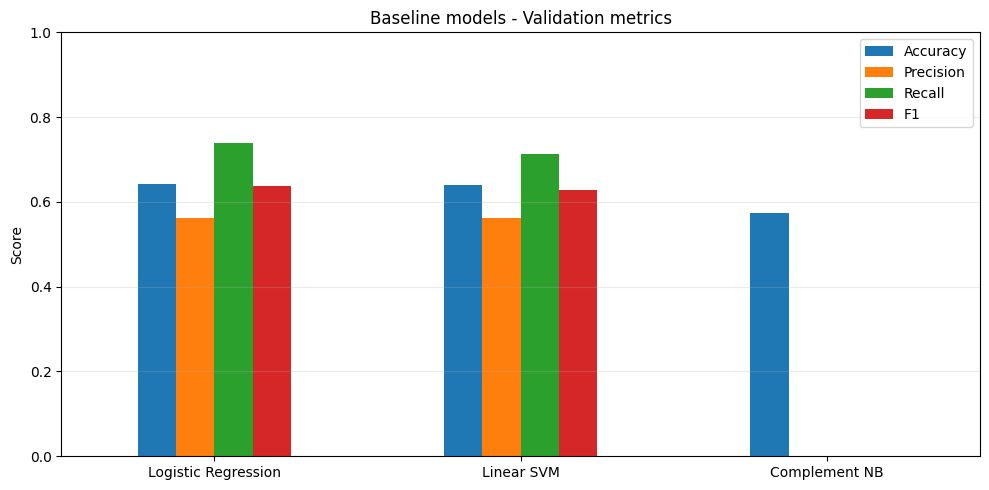

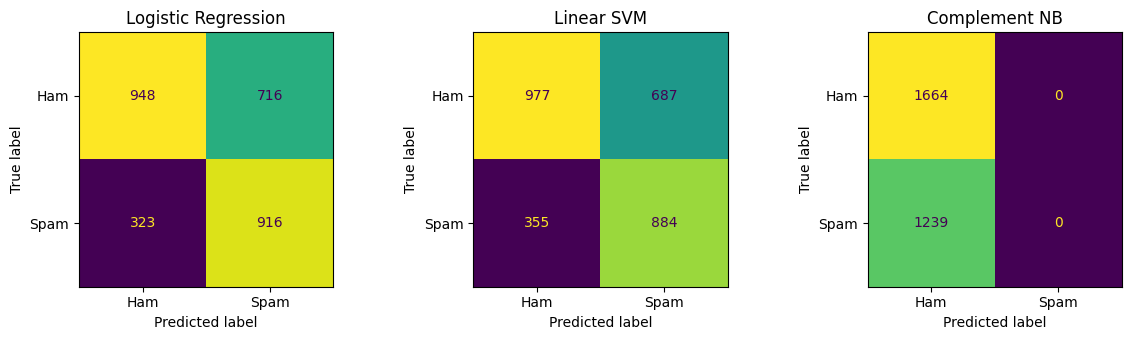

In [5]:
# Bảng tổng hợp các mô hình baseline trên Validation và lưu biểu đồ ma trận nhầm lẫn
results = {}
for name, prob in {"Logistic Regression": y_prob_lr, "Linear SVM": y_prob_svm, "Complement NB": y_prob_nb}.items():
    pred = (prob >= 0.5).astype(int)
    results[name] = {"Accuracy": accuracy_score(y_val, pred), "Precision": precision_score(y_val, pred, zero_division=0),
                     "Recall": recall_score(y_val, pred, zero_division=0), "F1": f1_score(y_val, pred, zero_division=0),
                     "F-beta (2)": fbeta_score(y_val, pred, beta=2, zero_division=0), "ROC-AUC": roc_auc_score(y_val, prob)}
comparison_df = pd.DataFrame(results).T.sort_values("F-beta (2)", ascending=False)
display(comparison_df.round(4))
ax = comparison_df[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0)
ax.set_title("Baseline models - Validation metrics"); ax.set_ylabel("Score"); ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "task2_baseline_comparison.png", dpi=300); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (name, prob) in zip(axes, {"Logistic Regression": y_prob_lr, "Linear SVM": y_prob_svm, "Complement NB": y_prob_nb}.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_val, (prob >= 0.5).astype(int)), display_labels=["Ham", "Spam"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "task2_baseline_confusion_matrices.png", dpi=300); plt.show()
